In [ ]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, when, count, hour, dayofweek, month
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator
import pandas as pd

In [ ]:
spark = SparkSession.builder \
   .appName("AirQualityPrediction") \
   .master("local[*]") \
   .getOrCreate()
print(f"Spark Session đã được khởi tạo. Phiên bản Spark: {spark.version}\n")

Spark Session đã được khởi tạo. Phiên bản Spark: 3.5.1



In [ ]:
file_path = 'air_quality_with_predicted_aqi.csv'
df = spark.read.csv(file_path, header=True, inferSchema=True)

In [ ]:
df.printSchema()

root
 |-- Station ID: double (nullable = true)
 |-- Location: string (nullable = true)
 |-- Station name: string (nullable = true)
 |-- Url: string (nullable = true)
 |-- CO: double (nullable = true)
 |-- Dew: double (nullable = true)
 |-- Humidity: double (nullable = true)
 |-- NO2: double (nullable = true)
 |-- O3: double (nullable = true)
 |-- Pressure: double (nullable = true)
 |-- PM10: double (nullable = true)
 |-- PM2.5: double (nullable = true)
 |-- SO2: double (nullable = true)
 |-- Temperature: double (nullable = true)
 |-- Wind: double (nullable = true)
 |-- Data Time S: timestamp (nullable = true)
 |-- Data Time Tz: string (nullable = true)
 |-- Status: string (nullable = true)
 |-- Alert level: string (nullable = true)
 |-- AQI_true: integer (nullable = true)
 |-- AQI_pred: double (nullable = true)



In [ ]:
df.show(10)

+----------+--------------------+--------------------+--------------------+----+----+--------+----+----+--------+-----+-----+----+-----------+----+-------------------+------------+------+-----------+--------+--------+
|Station ID|            Location|        Station name|                 Url|  CO| Dew|Humidity| NO2|  O3|Pressure| PM10|PM2.5| SO2|Temperature|Wind|        Data Time S|Data Time Tz|Status|Alert level|AQI_true|AQI_pred|
+----------+--------------------+--------------------+--------------------+----+----+--------+----+----+--------+-----+-----+----+-----------+----+-------------------+------------+------+-----------+--------+--------+
|    8767.0|10.782978,106.700711|Ho Chi Minh City ...|https://aqicn.org...| 5.0|22.9|    83.0|10.0| 6.5|  1009.0| 42.0|102.0| 5.0|       27.0| 3.6|2021-01-21 19:00:00|      +07:00|#NAME?|     #NAME?|     175| 174.995|
|    8688.0|21.0811211,105.81...|United Nations In...|https://aqicn.org...| 5.0|22.9|    77.0|10.0| 6.5|  1015.0| 42.0| 54.0| 5.

In [ ]:
df = df.withColumnRenamed("PM2.5", "PM25")

df.select(
    "CO", "NO2", "O3", "PM10", "PM25", "SO2",
    "Temperature", "Humidity", "Pressure", "Wind",
    "AQI_true", "AQI_pred"
).summary().show()


+-------+------------------+------------------+-----------------+------------------+-----------------+------------------+------------------+------------------+------------------+------------------+------------------+------------------+
|summary|                CO|               NO2|               O3|              PM10|             PM25|               SO2|       Temperature|          Humidity|          Pressure|              Wind|          AQI_true|          AQI_pred|
+-------+------------------+------------------+-----------------+------------------+-----------------+------------------+------------------+------------------+------------------+------------------+------------------+------------------+
|  count|              3415|              3415|             3415|              3415|             3415|              3415|              3415|              3415|              3415|              3415|              3415|              3415|
|   mean| 7.911303074670564|12.042079062957544|7.8376281

In [ ]:
from pyspark.sql.functions import col, when, regexp_replace, split, trim

df = df.withColumn(
    "Station name",
    when(
        col("Station name").isNotNull(),
        trim(
            split(
                regexp_replace(col("Station name"), r', Vietnam|\s*\(.*\)\s*', ''),
                '/'
            ).getItem(0)
        )
    )
)

df.select("Station name").show(truncate=False)

+--------------------------------------------+
|Station name                                |
+--------------------------------------------+
|Ho Chi Minh City US Consulate               |
|United Nations International School of Hanoi|
|Hanoi US Embassy                            |
|Gia Lai                                     |
|Thừa Thiên Huế                              |
|Hà Nội                                      |
|Bắc Ninh                                    |
|Lào Cai                                     |
|Ha Long                                     |
|Quảng Ninh                                  |
|Bắc Ninh                                    |
|Bắc Ninh                                    |
|Hà Nội                                      |
|Hà Nội                                      |
|Hà Nội                                      |
|Hà Nội                                      |
|Da Nang                                     |
|Nha Trang                                   |
|Hà Nội      

In [ ]:
df = df.drop("Station ID", "Location", "Url", "Status", "Alert level", "AQI_true","Data Time Tz")

In [ ]:
from pyspark.sql.functions import lit

df = df.fillna({"Station name": "Unknown"})

In [ ]:
from pyspark.sql import functions as F

df.select([F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in df.columns]).show()

+------------+---+---+--------+---+---+--------+----+----+---+-----------+----+-----------+--------+
|Station name| CO|Dew|Humidity|NO2| O3|Pressure|PM10|PM25|SO2|Temperature|Wind|Data Time S|AQI_pred|
+------------+---+---+--------+---+---+--------+----+----+---+-----------+----+-----------+--------+
|           0|  0|  0|       0|  0|  0|       0|   0|   0|  0|          0|   0|        793|       0|
+------------+---+---+--------+---+---+--------+----+----+---+-----------+----+-----------+--------+



In [ ]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window

w = Window.orderBy(F.monotonically_increasing_id()) \
           .rowsBetween(Window.unboundedPreceding, 0)

df = df.withColumn("last_valid_date", F.last("Data Time S", ignorenulls=True).over(w))

df = df.withColumn(
    "Data Time S",
    F.when(F.col("Data Time S").isNull(),
           F.date_add(F.col("last_valid_date"), 1))
     .otherwise(F.col("Data Time S"))
)

df = df.drop("last_valid_date")

In [ ]:
df.select([F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in df.columns]).show()

+------------+---+---+--------+---+---+--------+----+----+---+-----------+----+-----------+--------+
|Station name| CO|Dew|Humidity|NO2| O3|Pressure|PM10|PM25|SO2|Temperature|Wind|Data Time S|AQI_pred|
+------------+---+---+--------+---+---+--------+----+----+---+-----------+----+-----------+--------+
|           0|  0|  0|       0|  0|  0|       0|   0|   0|  0|          0|   0|          0|       0|
+------------+---+---+--------+---+---+--------+----+----+---+-----------+----+-----------+--------+



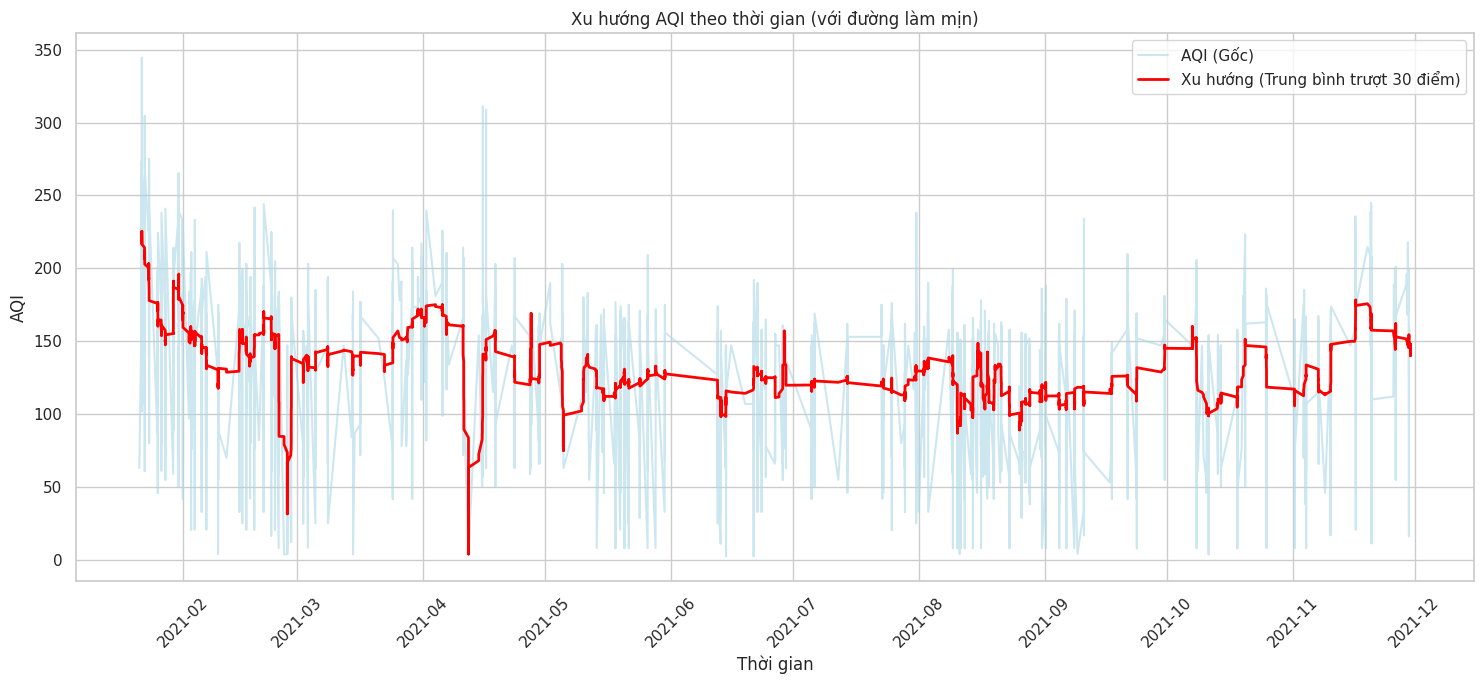

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pdf = df.select("Data Time S", "AQI_pred").orderBy("Data Time S").toPandas()

pdf['AQI_pred_smoothed'] = pdf['AQI_pred'].rolling(window=30, center=True).mean()

sns.set_theme(style="whitegrid")
plt.figure(figsize=(15, 7))

plt.plot(pdf["Data Time S"], pdf["AQI_pred"], color='lightblue', alpha=0.6, label='AQI (Gốc)')

plt.plot(pdf["Data Time S"], pdf['AQI_pred_smoothed'], color='red', linewidth=2, label='Xu hướng (Trung bình trượt 30 điểm)')

plt.xlabel("Thời gian")
plt.ylabel("AQI")
plt.title("Xu hướng AQI theo thời gian (với đường làm mịn)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
pdf = df.groupBy("Station name") \
        .agg(F.avg("AQI_pred").alias("AQI_mean")) \
        .toPandas()
print(pdf)

                                    Station name    AQI_mean
0                                        Da Nang  115.192412
1                               Hanoi US Embassy  174.708596
2                                       Bắc Ninh  139.862749
3                                         Hà Nội  134.799240
4                                      Nha Trang  147.000000
5                                        Ha Long  132.938070
6                                        Gia Lai   73.197500
7                                       Cao Bằng  155.831140
8                                        Unknown  147.000000
9                                        Lào Cai  107.422719
10                 Ho Chi Minh City US Consulate  147.103114
11                                Thừa Thiên Huế  132.807719
12                                    Quảng Ninh   73.565482
13  United Nations International School of Hanoi  145.076009


/tmp/ipython-input-2805795364.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


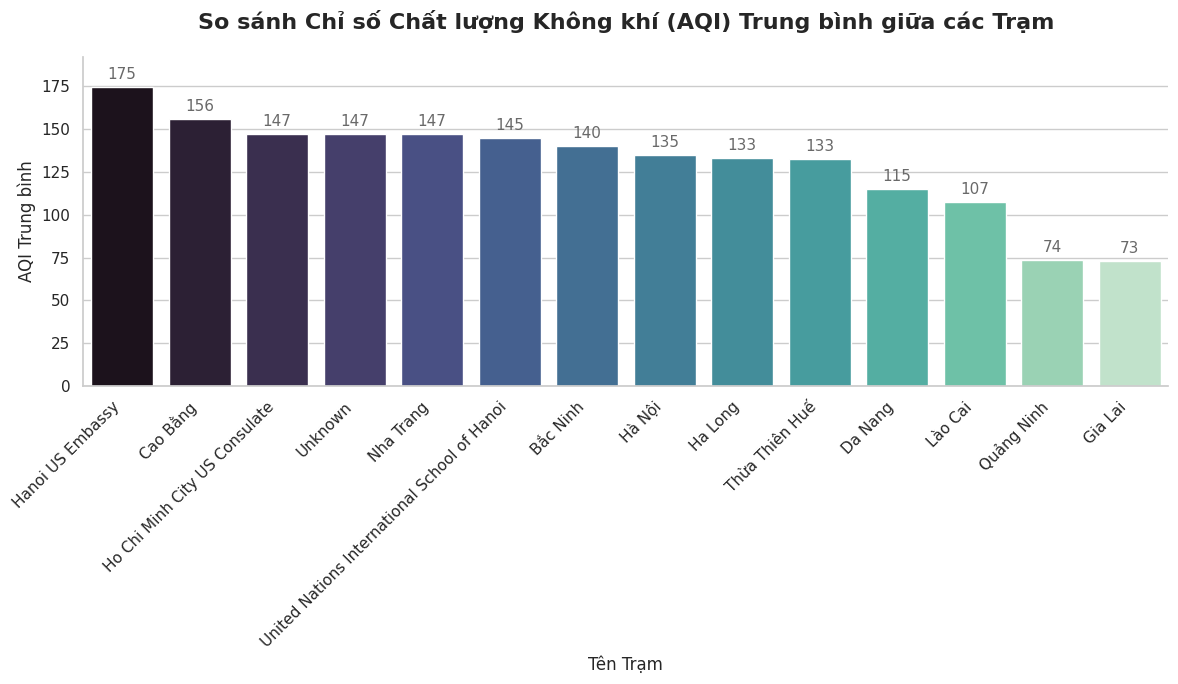

In [ ]:
pdf_sorted = pdf.sort_values('AQI_mean', ascending=False)
sns.set_style("whitegrid")
plt.figure(figsize=(12, 7))
ax = sns.barplot(
    x='Station name',
    y='AQI_mean',
    data=pdf_sorted,
    palette='mako'
)

for p in ax.patches:
    ax.annotate(
        f'{p.get_height():.0f}',
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center',
        va='center',
        xytext=(0, 9),
        textcoords='offset points',
        fontsize=11,
        color='dimgray'
    )

plt.title('So sánh Chỉ số Chất lượng Không khí (AQI) Trung bình giữa các Trạm', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Tên Trạm', fontsize=12)
plt.ylabel('AQI Trung bình', fontsize=12)
plt.xticks(rotation=45, ha='right')
ax.set_ylim(0, pdf_sorted['AQI_mean'].max() * 1.1)
sns.despine()
plt.tight_layout()
plt.show()

In [ ]:
label_col = "AQI_pred"
feature_cols =['CO', 'Dew', 'Humidity', 'NO2', 'O3', 'Pressure', 'PM10', 'PM25', 'SO2', 'Temperature', 'Wind']

In [ ]:
assembler = VectorAssembler(
    inputCols=feature_cols,
    outputCol="features"
)

In [ ]:
df_assembled = assembler.transform(df)

In [ ]:
(train_data, test_data) = df_assembled.randomSplit([0.8, 0.2], seed=42)
print(f"Number of training records: {train_data.count()}")
print(f"Number of testing records: {test_data.count()}")

Number of training records: 2780
Number of testing records: 635


In [ ]:
gbt = GBTRegressor(
    featuresCol="features",
    labelCol=label_col,
)
gbt_model = gbt.fit(train_data)

In [ ]:
lr = LinearRegression(
    featuresCol="features",
    labelCol=label_col)
lr_model = lr.fit(train_data)

In [ ]:
lr_predictions = lr_model.transform(test_data)
gbt_predictions = gbt_model.transform(test_data)

rmse_evaluator = RegressionEvaluator(labelCol=label_col, predictionCol="prediction", metricName="rmse")
mae_evaluator = RegressionEvaluator(labelCol=label_col, predictionCol="prediction", metricName="mae")
r2_evaluator = RegressionEvaluator(labelCol=label_col, predictionCol="prediction", metricName="r2")

lr_rmse = rmse_evaluator.evaluate(lr_predictions)
lr_mae = mae_evaluator.evaluate(lr_predictions)
lr_r2 = r2_evaluator.evaluate(lr_predictions)

gbt_rmse = rmse_evaluator.evaluate(gbt_predictions)
gbt_mae = mae_evaluator.evaluate(gbt_predictions)
gbt_r2 = r2_evaluator.evaluate(gbt_predictions)

print("--- Linear Regression Performance ---")
print(f"RMSE: {lr_rmse}")
print(f"MAE: {lr_mae}")
print(f"R-squared (R2): {lr_r2}")

print("\n--- Gradient-Boosted Tree Performance ---")
print(f"RMSE: {gbt_rmse}")
print(f"MAE: {gbt_mae}")
print(f"R-squared (R2): {gbt_r2}")

--- Linear Regression Performance ---
RMSE: 18.58717682646634
MAE: 15.236001988081078
R-squared (R2): 0.8104907200718666

--- Gradient-Boosted Tree Performance ---
RMSE: 5.4428404679120135
MAE: 1.851045370306277
R-squared (R2): 0.9837499451731425


In [ ]:
rmse_evaluator = RegressionEvaluator(labelCol=label_col, predictionCol="prediction", metricName="rmse")
mae_evaluator = RegressionEvaluator(labelCol=label_col, predictionCol="prediction", metricName="mae")
r2_evaluator = RegressionEvaluator(labelCol=label_col, predictionCol="prediction", metricName="r2")

paramGrid = ParamGridBuilder() \
   .addGrid(gbt.maxIter, [20, 50, 100]) \
   .addGrid(gbt.maxDepth, [5, 8, 10]) \
   .build()

crossval = CrossValidator(
    estimator=gbt,
    estimatorParamMaps=paramGrid,
    evaluator=rmse_evaluator,
    numFolds=3,
    seed=42
)

cv_model = crossval.fit(train_data)

best_gbt_model = cv_model.bestModel

best_gbt_predictions = best_gbt_model.transform(test_data)
tuned_gbt_rmse = rmse_evaluator.evaluate(best_gbt_predictions)
tuned_gbt_mae = mae_evaluator.evaluate(best_gbt_predictions)
tuned_gbt_r2 = r2_evaluator.evaluate(best_gbt_predictions)

print("\n--- Tuned Gradient-Boosted Tree Performance ---")
print(f"RMSE: {tuned_gbt_rmse}")
print(f"MAE: {tuned_gbt_mae}")
print(f"R-squared (R2): {tuned_gbt_r2}")


--- Tuned Gradient-Boosted Tree Performance ---
RMSE: 5.483381699023507
MAE: 1.791520130351576
R-squared (R2): 0.9835069651438947


In [ ]:
feature_importances = best_gbt_model.featureImportances
importance_df = pd.DataFrame(list(zip(feature_cols, feature_importances)),
                             columns=['feature', 'importance'])
importance_df = importance_df.sort_values(by='importance', ascending=False)

print("Tầm quan trọng của các đặc trưng từ mô hình GBT tốt nhất:")
print(importance_df)

Tầm quan trọng của các đặc trưng từ mô hình GBT tốt nhất:
        feature  importance
7          PM25    0.868385
0            CO    0.033532
8           SO2    0.025638
6          PM10    0.013185
9   Temperature    0.012230
4            O3    0.011794
3           NO2    0.011229
2      Humidity    0.007755
10         Wind    0.007688
5      Pressure    0.005408
1           Dew    0.003158


In [ ]:
spark.stop()
print("\nSpark Session đã được dừng.")


Spark Session đã được dừng.
